In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Mall_Customers.csv')
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Missing values:", df.isnull().sum().sum())
print("\nGender:\n", df['Gender'].value_counts())
df.describe().round(1)

Missing values: 0

Gender:
 Gender
Female    112
Male       88
Name: count, dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


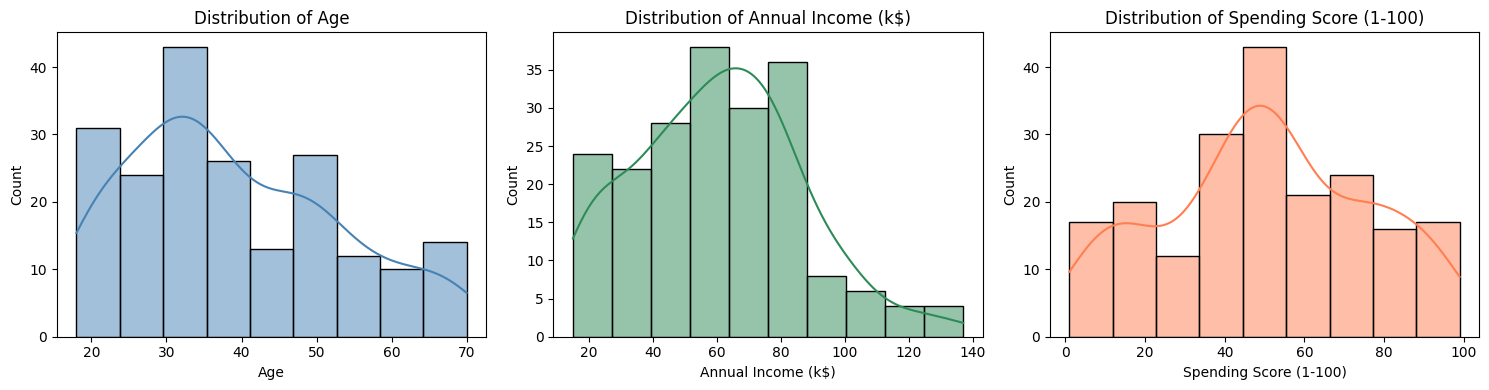

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
colors = ['steelblue', 'seagreen', 'coral']

for ax, col, c in zip(axes, cols, colors):
    sns.histplot(df[col], kde=True, ax=ax, color=c)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

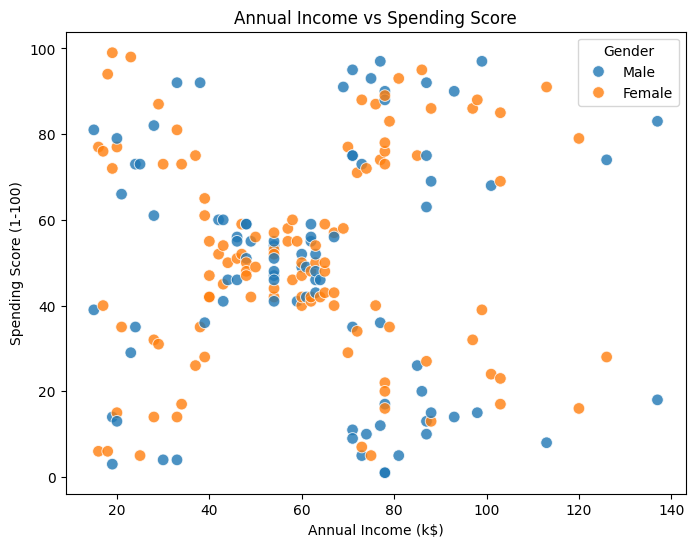

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Gender', s=70, alpha=0.8)
plt.title('Annual Income vs Spending Score')
plt.show()

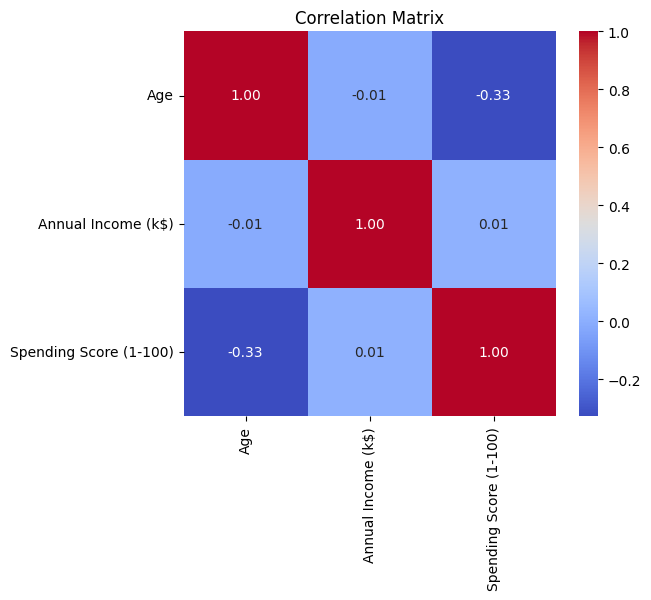

In [6]:
num_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [7]:
from sklearn.preprocessing import StandardScaler

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Before scaling:\n", X.head(3).values)
print("\nAfter scaling:\n", X_scaled[:3].round(2))
print("\nMean:", X_scaled.mean(axis=0).round(2), "| Std:", X_scaled.std(axis=0).round(2))

Before scaling:
 [[15 39]
 [15 81]
 [16  6]]

After scaling:
 [[-1.74 -0.43]
 [-1.74  1.2 ]
 [-1.7  -1.72]]

Mean: [-0. -0.] | Std: [1. 1.]


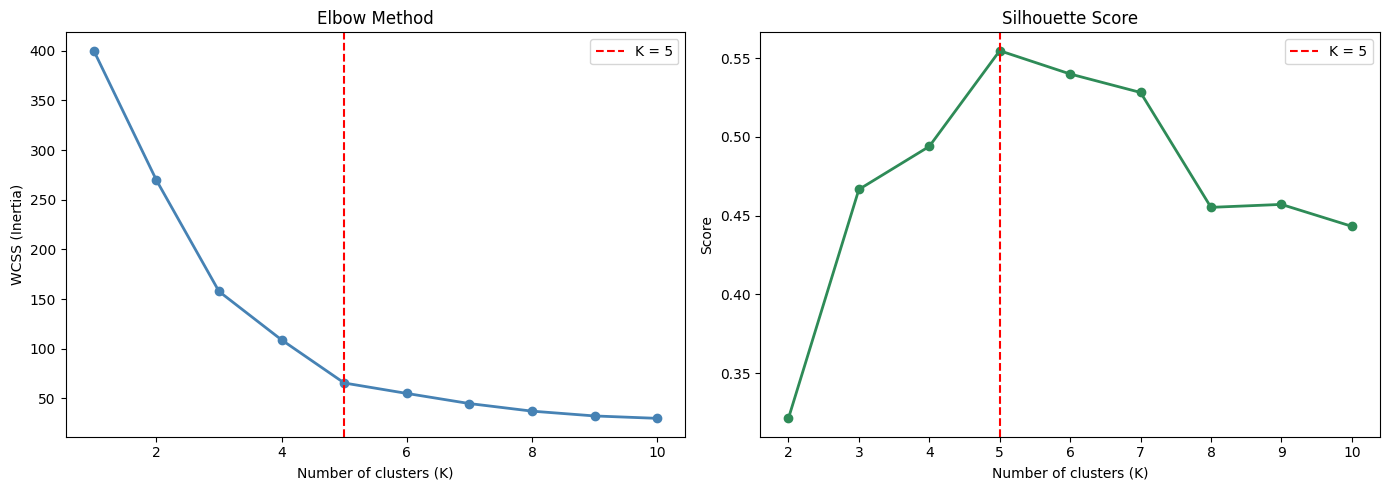

K=2: Silhouette = 0.321
K=3: Silhouette = 0.467
K=4: Silhouette = 0.494
K=5: Silhouette = 0.555
K=6: Silhouette = 0.540
K=7: Silhouette = 0.528
K=8: Silhouette = 0.455
K=9: Silhouette = 0.457
K=10: Silhouette = 0.443


In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
sil_scores = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    if k > 1:
        sil_scores.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, wcss, 'o-', color='steelblue', linewidth=2)
axes[0].axvline(x=5, color='red', linestyle='--', label='K = 5')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].legend()

axes[1].plot(range(2, 11), sil_scores, 'o-', color='seagreen', linewidth=2)
axes[1].axvline(x=5, color='red', linestyle='--', label='K = 5')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Score')
axes[1].legend()

plt.tight_layout()
plt.show()

for k, s in zip(range(2, 11), sil_scores):
    print(f"K={k}: Silhouette = {s:.3f}")

In [9]:
kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print("Customers per cluster:")
print(df['Cluster'].value_counts().sort_index())
print(f"\nSilhouette Score: {silhouette_score(X_scaled, df['Cluster']):.3f}")

Customers per cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Silhouette Score: 0.555


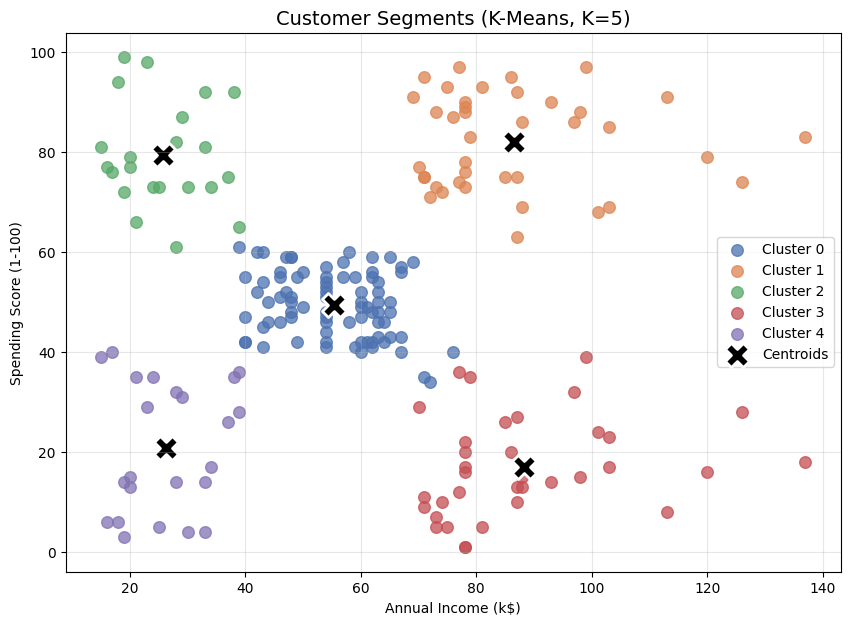

Centroids (Income, Spending):
  Cluster 0: Income = $55.3k | Spending = 49.5
  Cluster 1: Income = $86.5k | Spending = 82.1
  Cluster 2: Income = $25.7k | Spending = 79.4
  Cluster 3: Income = $88.2k | Spending = 17.1
  Cluster 4: Income = $26.3k | Spending = 20.9


In [10]:

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))
palette = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']

for i in range(5):
    cluster_data = df[df['Cluster'] == i]
    plt.scatter(cluster_data['Annual Income (k$)'],
                cluster_data['Spending Score (1-100)'],
                s=70, alpha=0.75, color=palette[i], label=f'Cluster {i}')

plt.scatter(centers[:, 0], centers[:, 1], s=300, c='black',
            marker='X', edgecolors='white', linewidths=2, label='Centroids')

plt.title('Customer Segments (K-Means, K=5)', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Centroids (Income, Spending):")
for i, c in enumerate(centers):
    print(f"  Cluster {i}: Income = ${c[0]:.1f}k | Spending = {c[1]:.1f}")

In [11]:
segment_names = {
    0: 'Standard',
    1: 'VIP (Target)',
    2: 'Impulsive Spenders',
    3: 'Careful Savers',
    4: 'Budget Shoppers'
}
df['Segment'] = df['Cluster'].map(segment_names)

profile = df.groupby('Segment').agg(
    Customers=('CustomerID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Income=('Annual Income (k$)', 'mean'),
    Avg_Spending=('Spending Score (1-100)', 'mean'),
    Female_pct=('Gender', lambda g: (g == 'Female').mean() * 100)
).round(1).sort_values('Avg_Spending', ascending=False)

profile

,Customers,Avg_Age,Avg_Income,Avg_Spending,Female_pct
Segment,,,,,
VIP (Target),39,32.7,86.5,82.1,53.8
Impulsive Spenders,22,25.3,25.7,79.4,59.1
Standard,81,42.7,55.3,49.5,59.3
Budget Shoppers,23,45.2,26.3,20.9,60.9
Careful Savers,35,41.1,88.2,17.1,45.7


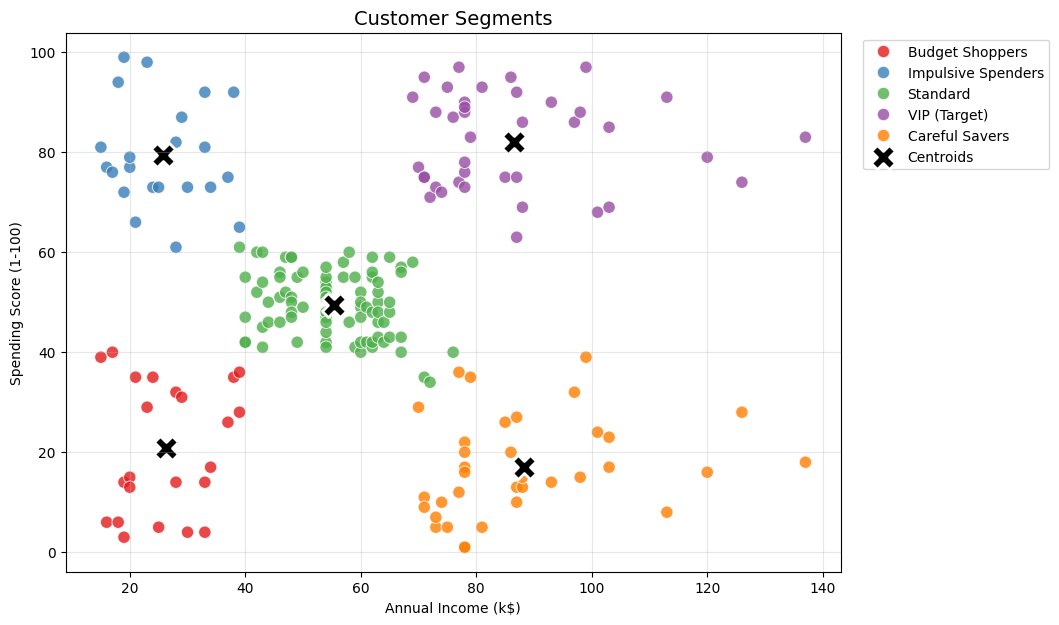

In [12]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Segment', palette='Set1', s=80, alpha=0.8)
plt.scatter(centers[:, 0], centers[:, 1], s=300, c='black',
            marker='X', edgecolors='white', linewidths=2, label='Centroids')
plt.title('Customer Segments', fontsize=14)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.show()

/tmp/ipykernel_530/232089367.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Segment', y='Age', palette='Set2',


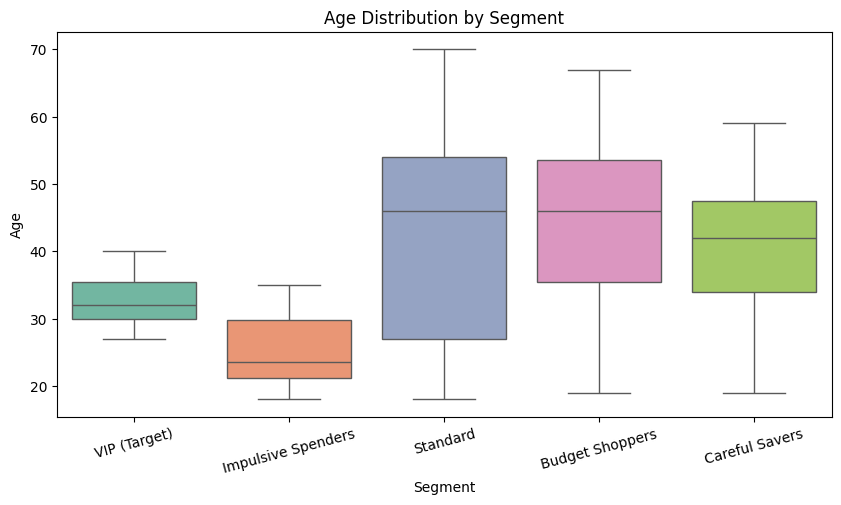

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Segment', y='Age', palette='Set2',
            order=profile.index)
plt.title('Age Distribution by Segment')
plt.xticks(rotation=15)
plt.show()

In [14]:
strategies = {
    'VIP (Target)': 'Loyalty program, early access & premium service',
    'Impulsive Spenders': 'Discounts, buy-now-pay-later & social media offers',
    'Standard': 'Seasonal offers & bundles to upgrade them',
    'Careful Savers': 'Quality-focused products & personalized experiences',
    'Budget Shoppers': 'Clearance sales & value deals'
}

def predict_segment(income, spending):
    new_customer = pd.DataFrame([[income, spending]],
                                columns=['Annual Income (k$)', 'Spending Score (1-100)'])
    scaled = scaler.transform(new_customer)
    cluster = kmeans.predict(scaled)[0]
    return segment_names[cluster]

tests = [(90, 85), (20, 80), (55, 50), (90, 10), (20, 10)]
for inc, sp in tests:
    seg = predict_segment(inc, sp)
    print(f"Income ${inc}k, Score {sp:>2} → {seg}")

Income $90k, Score 85 → VIP (Target)
Income $20k, Score 80 → Impulsive Spenders
Income $55k, Score 50 → Standard
Income $90k, Score 10 → Careful Savers
Income $20k, Score 10 → Budget Shoppers


In [16]:
print("🛍️ Customer Segment Predictor")
print("-" * 35)

try:
    income = float(input("Annual income (k$): "))
    spending = float(input("Spending score (1-100): "))

    if income <= 0 or not (1 <= spending <= 100):
        print("❌ Income must be positive and score between 1 and 100.")
    else:
        seg = predict_segment(income, spending)
        print(f"\n🎯 Segment: {seg}")
        print(f"💡 Strategy: {strategies[seg]}")
except ValueError:
    print("❌ Please enter numbers only.")

🛍️ Customer Segment Predictor
-----------------------------------
Annual income (k$): 90
Spending score (1-100): 85

🎯 Segment: VIP (Target)
💡 Strategy: Loyalty program, early access & premium service
